## Import Packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras._tf_keras.keras import layers
from keras._tf_keras.keras.models import Sequential
from keras._tf_keras.keras.layers import Dense,Flatten,Dropout,BatchNormalization
from keras._tf_keras.keras.losses import SparseCategoricalCrossentropy
from keras._tf_keras.keras.callbacks import EarlyStopping

## Set Constant Values

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 224
CHANNELS = 3

## Download or load the dataset 

In [3]:
training = "datasets/Plant Diseases/Rice/train/"
testing = "datasets/Plant Diseases/Rice/test/"

## Image Preprocessing

### Create Dataset for train,test,validation

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 3748 files belonging to 5 classes.
Using 2999 files for training.


In [5]:
test_ds = tf.keras.utils.image_dataset_from_directory(
  testing,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 939 files belonging to 5 classes.
Using 752 files for training.


In [6]:
val_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 3748 files belonging to 5 classes.
Using 749 files for validation.


In [7]:
class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

['Brown spot', 'Healthy', 'Hispa', 'Leaf blast', 'Neck blast']


## Visualize the data

In [8]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 224, 224, 3)
(32,)


## Configure the dataset for performance

In [9]:
trian_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

## Standardize the data

In [10]:
normalization_layer = layers.Rescaling(1./255)

In [11]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0 1.0


## Resize and Rescale

In [12]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(0.1 / 256)
])

## Data Augmentation

In [13]:
data_augmentation  = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2)
])

In [14]:
train_ds = train_ds.map(
    lambda x,y: (data_augmentation(x, training=True),y),
).prefetch(buffer_size = tf.data.AUTOTUNE)

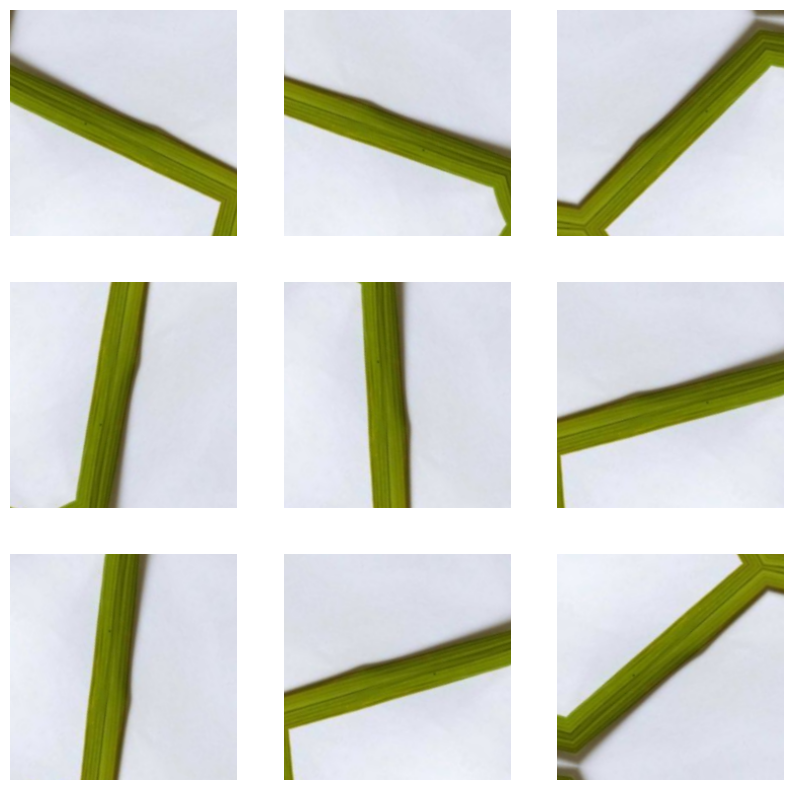

In [15]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

Define the EarlyStopping callback

In [16]:
early_stopping = EarlyStopping(
    monitor='val_loss',  # or 'val_accuracy' depending on your goal
    patience=3,          # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True,  # Restore model weights from the epoch with the best value of the monitored quantity
    verbose=1
)

# ResNet Model Implementation

Import the base model

In [53]:
from keras._tf_keras.keras.applications import ResNet152

Create a base model

In [55]:
conv_base = ResNet152(
    weights='imagenet',
    include_top=False,
    input_shape=(IMAGE_SIZE,IMAGE_SIZE,CHANNELS)
)
conv_base.trainable = False

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 23s 0us/step


Add Connected layers to ResNet Base

In [56]:
model_res = Sequential()
resize_and_rescale
model_res.add(conv_base)
model_res.add(Flatten())
model_res.add(Dense(256,activation='relu'))
model_res.add(Dropout(0.5))
model_res.add(BatchNormalization())
model_res.add(Dense(num_classes,activation='sigmoid'))
model_res.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,063,621 (320.68 MB)

 Trainable params: 25,692,165 (98.01 MB)

 Non-trainable params: 58,371,456 (222.67 MB)

Compile the model

In [57]:
model_res.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

### Train the model

In [58]:
epochs = 5
history = model_res.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    callbacks=early_stopping
)

Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 825s 9s/step - accuracy: 0.5361 - loss: 1.2461 - val_accuracy: 0.7263 - val_loss: 0.7423
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 815s 9s/step - accuracy: 0.6792 - loss: 0.7917 - val_accuracy: 0.7597 - val_loss: 0.6088
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 807s 9s/step - accuracy: 0.7120 - loss: 0.7064 - val_accuracy: 0.7810 - val_loss: 0.5632
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 820s 9s/step - accuracy: 0.7402 - loss: 0.6365 - val_accuracy: 0.7917 - val_loss: 0.5250
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 816s 9s/step - accuracy: 0.7799 - loss: 0.5742 - val_accuracy: 0.7957 - val_loss: 0.5554
Restoring model weights from the end of the best epoch: 4.


### Evaluate the model

In [59]:
model_res.evaluate(test_ds)

24/24 ━━━━━━━━━━━━━━━━━━━━ 186s 8s/step - accuracy: 0.7965 - loss: 0.5133


[0.5392901301383972, 0.7859042286872864]

# Visualize training results

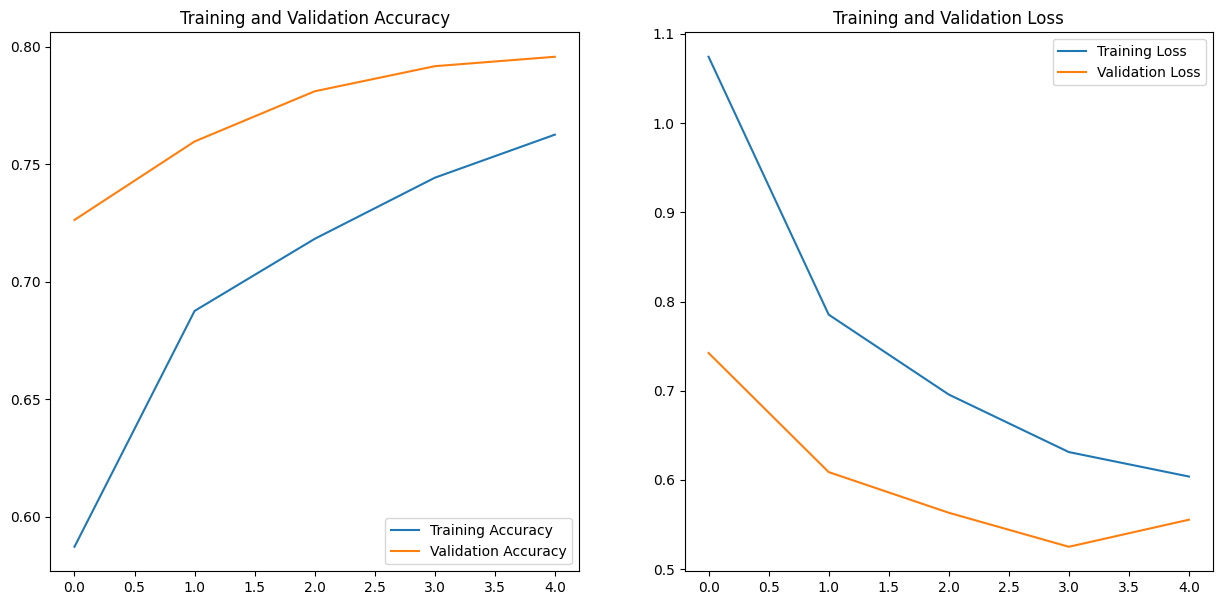

In [60]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']

val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## Save the model

In [61]:
model_res.save("Model ResNet.keras")

# DenseNet Model Implementation

In [17]:
from keras._tf_keras.keras.applications import DenseNet121
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [18]:
model_dense = Sequential()
resize_and_rescale
model_dense.add(base_model)
model_dense.add(Flatten())
model_dense.add(Dense(256,activation='relu'))
model_dense.add(Dropout(0.5))
model_dense.add(BatchNormalization())
model_dense.add(Dense(num_classes,activation='sigmoid'))
model_dense.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,885,125 (75.86 MB)

 Trainable params: 12,847,109 (49.01 MB)

 Non-trainable params: 7,038,016 (26.85 MB)

In [19]:
model_dense.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

Train the model

In [20]:
epochs = 5
history = model_dense.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    callbacks=early_stopping
)

Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 330s 3s/step - accuracy: 0.5696 - loss: 1.1665 - val_accuracy: 0.6756 - val_loss: 0.8767
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 306s 3s/step - accuracy: 0.6919 - loss: 0.7844 - val_accuracy: 0.7143 - val_loss: 0.6818
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 336s 4s/step - accuracy: 0.7278 - loss: 0.6986 - val_accuracy: 0.6729 - val_loss: 0.7573
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 325s 3s/step - accuracy: 0.7467 - loss: 0.6590 - val_accuracy: 0.7250 - val_loss: 0.6651
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 311s 3s/step - accuracy: 0.7387 - loss: 0.6742 - val_accuracy: 0.7343 - val_loss: 0.6380
Restoring model weights from the end of the best epoch: 5.


Evaluate the model

In [21]:
model_dense.evaluate(test_ds)

24/24 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.7500 - loss: 0.6208


[0.6496269702911377, 0.7433510422706604]

Visualize training accuracy and loss

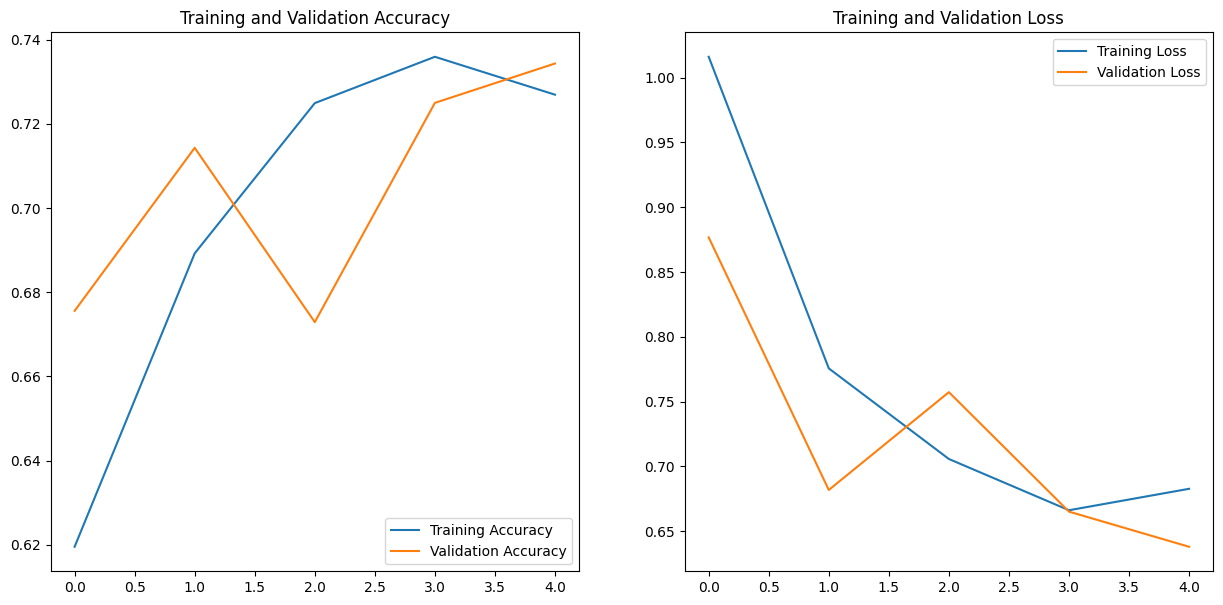

In [22]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']

val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

Save the model

In [23]:
model_dense.save('Model DenseNet.keras')

# EfficientNet Model Implemantation

Import Base Model

In [24]:
from keras._tf_keras.keras.applications.efficientnet_v2 import EfficientNetV2B0
base_eff = EfficientNetV2B0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_eff.trainable = False

Add connected layers to base model

In [25]:
model_eff = Sequential()
resize_and_rescale
model_eff.add(base_eff)
model_eff.add(Flatten())
model_eff.add(Dense(256,activation='relu'))
model_eff.add(Dropout(0.5))
model_eff.add(BatchNormalization())
model_eff.add(Dense(num_classes,activation='sigmoid'))
model_eff.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    16,056,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,978,197 (83.84 MB)

 Trainable params: 16,058,373 (61.26 MB)

 Non-trainable params: 5,919,824 (22.58 MB)

Compile the model

In [26]:
model_eff.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

Train the model

In [27]:
epochs = 15
history = model_eff.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    callbacks=early_stopping
)

Epoch 1/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.5154 - loss: 1.3140 - val_accuracy: 0.7677 - val_loss: 0.6206
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.6830 - loss: 0.7754 - val_accuracy: 0.7904 - val_loss: 0.5575
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.7342 - loss: 0.6535 - val_accuracy: 0.8131 - val_loss: 0.5068
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.7618 - loss: 0.6042 - val_accuracy: 0.8291 - val_loss: 0.4742
Epoch 5/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.7654 - loss: 0.5757 - val_accuracy: 0.8331 - val_loss: 0.4425
Epoch 6/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.7776 - loss: 0.5562 - val_accuracy: 0.8224 - val_loss: 0.4503
Epoch 7/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.7889 - loss: 0.5371 - val_accuracy: 0.8304 - val_loss: 0.4346
Epoch 8/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.8100 - loss: 0.4889 - val_accuracy: 0.8011 - v

Evaluate the Model

In [28]:
model_eff.evaluate(test_ds)

24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 693ms/step - accuracy: 0.8175 - loss: 0.4404


[0.4490540623664856, 0.8204787373542786]

# Visualize training accuracy and losses

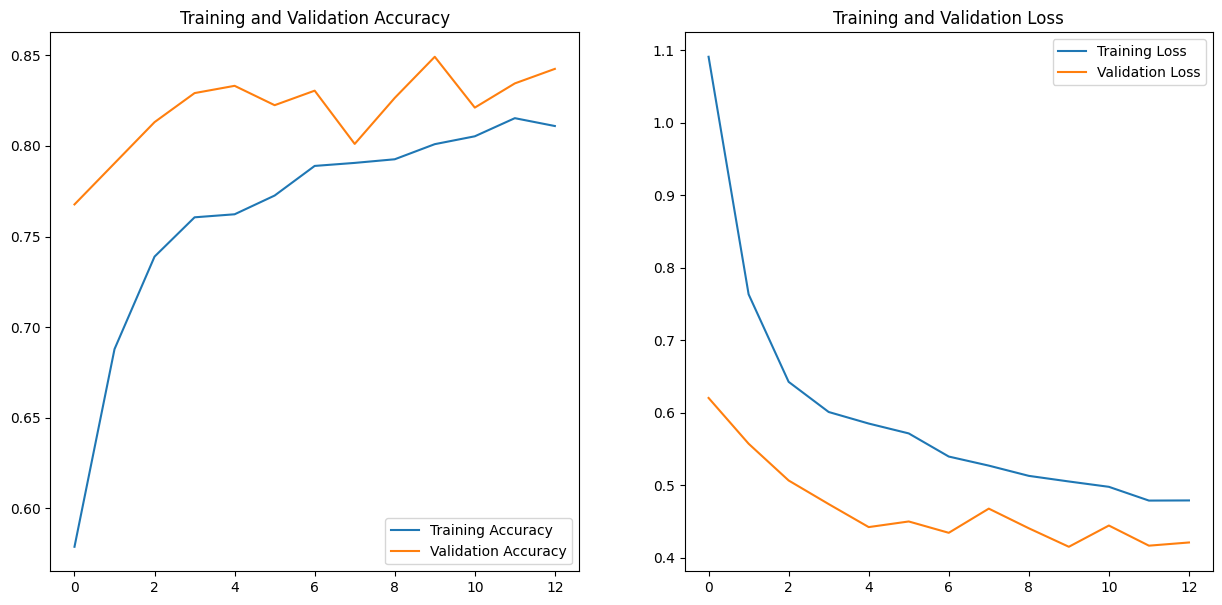

In [30]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']

val_loss = history.history['val_loss']

epochs_range = range(13)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

Save the Model

In [31]:
model_eff.save('Model EfficientNet.keras')